## Heuristic Method

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("andrewmvd/sp-500-stocks")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Pasindu.Kodikara\.cache\kagglehub\datasets\andrewmvd\sp-500-stocks\versions\1023


In [2]:
import pandas as pd

In [3]:
df_companies = pd.read_csv(f"{path}/sp500_companies.csv")
df_stocks    = pd.read_csv(f"{path}/sp500_stocks.csv",  parse_dates=['Date'])
df_index     = pd.read_csv(f"{path}/sp500_index.csv",   parse_dates=['Date'])

## Overview

**Problem (same as the exact notebook).** From the S&P 500 stocks that have price data, choose **at most K** stocks and decide the **weight** of each, so that the portfolio's mean absolute deviation (MAD) is as low as possible while the expected daily return stays at or above a target. A held stock must carry a weight between a minimum and a maximum.

**This notebook is the heuristic method.** It uses **Simulated Annealing (SA) over stock subsets** in a hybrid scheme:

| Level | Decides | Method |
|---|---|---|
| Outer search | *which* K stocks are held | Simulated Annealing, neighbour = swap one held stock for one unheld stock |
| Inner solver | the *weights* of a fixed subset | a small LP (convex, so its optimum is global for that subset) |

The results are compared with the exact MILP (Branch and Bound) in `results/exact_results.csv` on **identical inputs**: same data, same universes, same K, bounds and target rule, same MAD objective, and the same independent feasibility checker.

| Part | Content |
|---|---|
| 1-2 | Data and helper functions, copied from `Exact_Method.ipynb` |
| 3-4 | Exact reference loaded; inner solver validated against it and timed |
| 5 | Simulated Annealing |
| 6 | Tuning on a separate universe that is not reported |
| 7 | Main experiment: 10 SA seeds on all 12 reference instances |
| 8 | Ablation: start only, local search, full SA |
| 9 | Plots |
| 10 | Findings, limits, future work |

**Course links.** Exact versus heuristic methods: Lecture 1 slides 55-57. Stochastic methods: Lecture 1 slides 60-64. Local and global optima: Lecture 1 slides 65-66. No free lunch: Lecture 1 slides 70-71. Penalty methods: Lecture 8 slides 28-37. Convexity of the inner problem: Lecture 2 slides 97-106. Bounds and gaps: Lecture 5 slides 23-28. Simulated annealing itself is only named in the slides, so the design follows Kochenderfer and Wheeler, *Algorithms for Optimization* (stochastic methods chapter) and Yang, *Engineering Optimization*.

In [4]:
import time
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import milp, linprog, LinearConstraint, Bounds

SEED = 42
pd.set_option("display.precision", 5)
pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

In [5]:
import os, platform, sys
import scipy
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")
print(f"machine: {platform.processor() or platform.machine()} | logical CPUs: {os.cpu_count()} | OS: {platform.platform()}")

Python 3.13.5 | numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1
machine: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel | logical CPUs: 20 | OS: Windows-11-10.0.26100-SP0


## 1. Data and modelling choices

The next cell is copied **verbatim** from `Exact_Method.ipynb` (section 2), so prices become returns in exactly the same way. `QUICK = True` also shortens this notebook (fewer sizes, universes and SA seeds) for a fast test run.

In [6]:
# ---- Modelling choices (change here) ----
WINDOW_ROWS = 500
K = 5
LOWER, UPPER = 0.02, 0.30
TARGET_FRAC = 0.7
TIME_LIMIT = 60
REL_GAP = 1e-4
SIZES = [20, 50, 100, 170]      # universe sizes (capped at the number of complete stocks)
SEEDS = [0, 1, 2]               # different random universes per size
QUICK = False                   # True = fewer sizes/seeds for a fast test run
if QUICK:
    SIZES, SEEDS = [20, 50], [0]
assert K * UPPER >= 1, "the budget cannot be spent: increase K or UPPER"

# ---- Prices -> returns ----
wide = df_stocks.pivot_table(index="Date", columns="Symbol", values="Adj Close", aggfunc="last").sort_index()
window = wide.iloc[-WINDOW_ROWS:]
complete = window.loc[:, window.notna().all()]                 # keep only stocks with a full history in the window
returns_all = complete.pct_change().iloc[1:]                    # simple daily returns
T_DAYS, N_ALL = returns_all.shape
SIZES = sorted({min(n, N_ALL) for n in SIZES})

print(f"window: {window.index[0].date()} -> {window.index[-1].date()} ({len(window)} price rows)")
print(f"stocks with any price: {wide.shape[1]} | complete in the window: {N_ALL}")
print(f"returns: T = {T_DAYS} days x {N_ALL} stocks | universe sizes used: {SIZES}")
print("non-positive prices:", int((window <= 0).sum().sum()), "| NaN returns:", int(returns_all.isna().sum().sum()))

window: 2022-12-27 -> 2024-12-20 (500 price rows)
stocks with any price: 172 | complete in the window: 170
returns: T = 499 days x 170 stocks | universe sizes used: [20, 50, 100, 170]
non-positive prices: 0 | NaN returns: 0


## 2. Helper functions (copied verbatim)

`mad`, `variance`, `check_portfolio`, `max_feasible_return`, `return_target`, `get_universe` (exact notebook section 4), `best_weights_for_subset` (section 5.2) and `solve_mad_milp` (section 5). `solve_mad_milp` is used here only to (a) build a reference on the tuning universe and (b) re-time the exact method on **this** machine, so both methods are timed on the same hardware.

In [7]:
def mad(R, w):
    # mean absolute deviation of the portfolio's daily return
    R = np.asarray(R, float); w = np.asarray(w, float)
    return float(np.mean(np.abs((R - R.mean(axis=0)) @ w)))


def variance(R, w):
    w = np.asarray(w, float)
    return float(w @ np.cov(np.asarray(R, float), rowvar=False) @ w)


def check_portfolio(w, mu, k, lower, upper, target, tol=1e-6):
    # re-verify all constraints: budget, no shorting, cardinality, weight bounds, return target
    w = np.asarray(w, float); held = w > tol; problems = []
    if abs(w.sum() - 1) > tol:
        problems.append(f"weights sum to {w.sum():.8f}")
    if (w < -tol).any():
        problems.append("negative weight")
    if held.sum() > k:
        problems.append(f"{int(held.sum())} stocks held, limit {k}")
    if held.any() and (w[held] < lower - tol).any():
        problems.append("a held stock is below the minimum weight")
    if (w > upper + tol).any():
        problems.append("a weight exceeds the maximum")
    ret = float(np.asarray(mu) @ w)
    if ret < target - tol:
        problems.append(f"expected return {ret:.6f} below target {target:.6f}")
    return {"feasible": not problems, "problems": problems, "n_held": int(held.sum()), "expected_return": ret}


def max_feasible_return(mu, k, upper):
    # best expected return with at most k stocks, each weight <= upper (ignores the lower bound: slightly optimistic)
    remaining, total = 1.0, 0.0
    for m in np.sort(mu)[::-1][:k]:
        take = min(upper, remaining)
        total += take * m
        remaining -= take
    return total


def return_target(mu, k, upper, frac):
    base = float(np.mean(mu))                      # equal-weight return over the universe
    return base + frac * (max_feasible_return(mu, k, upper) - base)


def get_universe(n, seed):
    rng = np.random.default_rng(SEED + 1000 * seed + n)
    cols = sorted(rng.choice(returns_all.columns.to_numpy(), size=n, replace=False))
    return returns_all[cols]

In [8]:
def best_weights_for_subset(R, idx, lower, upper, target):
    # LP over the weights of a fixed subset: min mean absolute deviation (all chosen stocks are held)
    T = R.shape[0]; k = len(idx)
    mu = R.mean(axis=0); D = (R - mu)[:, idx]
    c = np.r_[np.zeros(k), np.full(T, 1.0 / T)]
    A_ub = np.vstack([np.hstack([D, -np.eye(T)]), np.hstack([-D, -np.eye(T)]), np.r_[-mu[idx], np.zeros(T)][None, :]])
    b_ub = np.r_[np.zeros(2 * T), -target]
    A_eq = np.r_[np.ones(k), np.zeros(T)][None, :]
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[1.0],
                  bounds=[(lower, upper)] * k + [(0, None)] * T, method="highs")
    return (res.fun, res.x[:k]) if res.status == 0 else (None, None)

In [9]:
STATUS = {0: "Optimal", 1: "Time limit", 2: "Infeasible", 3: "Unbounded", 4: "Other"}


def solve_mad_milp(R, k, lower, upper, target, integer=True, time_limit=60, rel_gap=1e-4):
    R = np.asarray(R, float)
    T, N = R.shape
    mu = R.mean(axis=0)
    D = sp.csr_matrix(R - mu)
    I_T, I_N = sp.identity(T, format="csr"), sp.identity(N, format="csr")
    zT, zN = sp.csr_matrix((T, N)), sp.csr_matrix((N, N))
    row = lambda a, b, c: sp.hstack([sp.csr_matrix(np.atleast_2d(a)), sp.csr_matrix(np.atleast_2d(b)), sp.csr_matrix(np.atleast_2d(c))])

    A = sp.vstack([
        sp.hstack([-D, zT, I_T]),                         # (2) d_t >=  D_t w
        sp.hstack([D, zT, I_T]),                          # (3) d_t >= -D_t w
        row(mu, np.zeros(N), np.zeros(T)),                # (4) return target
        row(np.ones(N), np.zeros(N), np.zeros(T)),        # (5) budget
        row(np.zeros(N), np.ones(N), np.zeros(T)),        # (6) cardinality
        sp.hstack([I_N, -lower * I_N, sp.csr_matrix((N, T))]),   # (7) w >= lower * z
        sp.hstack([I_N, -upper * I_N, sp.csr_matrix((N, T))]),   # (7) w <= upper * z
    ]).tocsr()
    lo = np.r_[np.zeros(2 * T), target, 1.0, -np.inf, np.zeros(N), np.full(N, -np.inf)]
    hi = np.r_[np.full(2 * T, np.inf), np.inf, 1.0, k, np.full(N, np.inf), np.zeros(N)]
    c = np.r_[np.zeros(2 * N), np.full(T, 1.0 / T)]
    integrality = np.r_[np.zeros(N), np.ones(N) if integer else np.zeros(N), np.zeros(T)]
    bounds = Bounds(np.zeros(2 * N + T), np.r_[np.ones(2 * N), np.full(T, np.inf)])

    t0 = time.perf_counter()
    res = milp(c, constraints=LinearConstraint(A, lo, hi), integrality=integrality, bounds=bounds,
               options={"time_limit": time_limit, "mip_rel_gap": rel_gap, "disp": False})
    elapsed = time.perf_counter() - t0

    w = res.x[:N] if res.x is not None else None
    w = np.where(w < 1e-9, 0.0, w) if w is not None else None
    return {"status": res.status, "status_text": STATUS.get(res.status, "Other"), "time": elapsed,
            "obj": res.fun if res.x is not None else np.nan,
            "bound": getattr(res, "mip_dual_bound", np.nan) if integer else (res.fun if res.x is not None else np.nan),
            "gap": getattr(res, "mip_gap", np.nan) if integer else np.nan,
            "nodes": getattr(res, "mip_node_count", np.nan) if integer else np.nan,
            "w": w, "mad": mad(R, w) if w is not None else np.nan,
            "n_vars": 2 * N + T, "n_cons": 2 * T + 2 * N + 3}

## 3. The exact reference

`results/exact_results.csv` holds 12 instances: 10 `base` (K = 5, target fraction 0.7, N = 20, 50, 100 with universe seeds 0-2 and N = 170 once) and 2 `hard` (K = 8, fraction 0.5, N = 100 and 170). The first check confirms that this notebook rebuilds **the same data and the same universes**: the return target depends on the mean return of every stock in the universe, so it only matches to machine precision if the universe and the returns are identical.

In [10]:
exact = pd.read_csv("results/exact_results.csv")
assert len(exact) == 12 and {"config", "status", "objective_mad", "best_bound", "selected"} <= set(exact.columns)
assert returns_all.shape == (499, 170), returns_all.shape
if QUICK:
    exact = exact[exact.N.isin(SIZES) & exact.seed.isin(SEEDS)].reset_index(drop=True)


def instance(row):
    # rebuild one reference instance exactly as the exact notebook did
    U = get_universe(int(row.N), int(row.seed)); R = U.to_numpy(); mu = R.mean(axis=0)
    return U, R, mu, return_target(mu, int(row.K), UPPER, float(row.target_frac))


target_err = max(abs(instance(r)[3] - r.target) for r in exact.itertuples())
print(f"{len(exact)} reference instances | largest difference between rebuilt and saved return targets: {target_err:.1e}")
assert target_err < 1e-12
exact[["config", "N", "seed", "K", "target_frac", "status", "objective_mad", "best_bound", "mip_gap", "runtime_s", "nodes", "selected"]]

12 reference instances | largest difference between rebuilt and saved return targets: 9.5e-17


,config,N,seed,K,target_frac,status,objective_mad,best_bound,mip_gap,runtime_s,nodes,selected
0,base,20,0,5,0.7,Optimal,0.00757,0.00757,0.00000,1.82982,72,"FOXA,IP,IRM,TDG,TTWO"
1,base,20,1,5,0.7,Optimal,0.00734,0.00734,0.00000,0.82150,1,"FOXA,LRCX,PEG,T,TT"
2,base,20,2,5,0.7,Optimal,0.00748,0.00748,0.00000,1.12806,1,"AXON,CRM,GOOG,TJX,WELL"
3,base,50,0,5,0.7,Optimal,0.00950,0.00950,0.00000,5.44222,5,"AMZN,CME,IRM,NVDA,PH"
4,base,50,1,5,0.7,Optimal,0.00804,0.00804,0.00000,3.36631,41,"ANET,CME,PGR,PHM,UAL"
5,base,50,2,5,0.7,Optimal,0.00956,0.00956,0.00000,3.96526,5,"AXON,GDDY,META,NVDA,T"
6,base,100,0,5,0.7,Optimal,0.00966,0.00966,0.00000,10.63831,11,"GDDY,META,NVDA,PKG,WELL"
7,base,100,1,5,0.7,Optimal,0.00946,0.00946,0.00000,9.24970,9,"AXON,META,NVDA,PGR,T"
8,base,100,2,5,0.7,Optimal,0.00849,0.00849,0.00000,10.49130,83,"ANET,GDDY,META,PGR,WELL"
9,base,170,0,5,0.7,Optimal,0.00974,0.00974,0.00000,27.99689,7,"AXON,GDDY,META,NVDA,PGR"


## 4. The inner solver

### 4.1 Validation against the exact results

For every reference instance we take the stocks the MILP selected, solve the inner LP (`best_weights_for_subset`, verbatim) on that subset, and compare with the MILP objective. Because the inner problem is a convex LP (Lecture 2 slides 97-106), its optimum is the global optimum *for that subset*, so it must reproduce the MILP value.

In [11]:
rows_v = []
for r in exact.itertuples():
    U, R, mu, target = instance(r)
    idx = [U.columns.get_loc(s) for s in r.selected.split(",")]
    val, _ = best_weights_for_subset(R, idx, LOWER, UPPER, target)
    rows_v.append(dict(config=r.config, N=r.N, seed=r.seed, exact_mad=r.objective_mad, inner_lp_mad=val, abs_diff=abs(val - r.objective_mad)))
validation = pd.DataFrame(rows_v)
print(f"largest difference: {validation.abs_diff.max():.1e}")
assert validation.abs_diff.max() < 1e-6, "inner LP does not reproduce the exact objective: stop and fix"
validation

largest difference: 4.6e-10


,config,N,seed,exact_mad,inner_lp_mad,abs_diff
0,base,20,0,0.00757,0.00757,6.07153e-18
1,base,20,1,0.00734,0.00734,4.59427e-10
2,base,20,2,0.00748,0.00748,6.15827e-17
3,base,50,0,0.00950,0.00950,9.19403e-17
4,base,50,1,0.00804,0.00804,5.20417e-17
5,base,50,2,0.00956,0.00956,9.96252e-15
6,base,100,0,0.00966,0.00966,1.16400e-15
7,base,100,1,0.00946,0.00946,3.49894e-15
8,base,100,2,0.00849,0.00849,7.28584e-17
9,base,170,0,0.00974,0.00974,1.31839e-16


### 4.2 A faster inner solver and an LP-free feasibility test

The search calls the inner solver hundreds of times, so its speed sets the budget. Two changes, both checked below against the verbatim code:

1. **Same LP, smaller form.** Instead of $d_t \ge \pm a_t$ (2T inequality rows), write $a_t = p_t - n_t$ with $p_t, n_t \ge 0$ and minimise $\frac{1}{T}\sum_t (p_t + n_t)$: T equality rows and sparse matrices. At the optimum $p_t + n_t = |a_t|$ (the free-variable split, Lecture 3 slides 22-28), so the optimum is identical.
2. **Feasibility without an LP.** For a fixed subset where every stock is held, the highest reachable expected return is found greedily: each stock gets `LOWER`, the remaining budget goes to the stocks with the highest mean, up to `UPPER` each. If that is below the target, the subset is infeasible and no LP is needed.

**Consequence: the top-K start is always feasible when any K-subset is.** The greedy weights depend only on the *rank* of each stock, not on its value: the best return of a subset is $\sum_j c_j\, m_{(j)}$ with fixed $c_j \ge 0$ and $m_{(1)} \ge \dots \ge m_{(K)}$ the sorted means. The $j$-th best mean of the whole universe is at least the $j$-th best mean of any subset, so the K highest-mean stocks reach the highest return of all K-subsets. So no fallback start is needed.

Each subset's result is **cached by `frozenset(subset)`**, so a revisited subset costs a dictionary lookup.

In [12]:
def subset_max_return(mu_s, lower, upper):
    # highest expected return of a fixed subset when every stock is held: all get `lower`, the rest goes to the best ones up to `upper`
    m = np.sort(np.asarray(mu_s, float))[::-1]
    rem, total = 1.0 - len(m) * lower, lower * m.sum()
    for v in m:
        take = min(upper - lower, rem)
        total += take * v
        rem -= take
    return total


def max_return_weights(mu_s, lower, upper):
    # the weights that reach subset_max_return (used by the penalty variant)
    w = np.full(len(mu_s), lower); rem = 1.0 - len(mu_s) * lower
    for j in np.argsort(mu_s)[::-1]:
        take = min(upper - lower, rem); w[j] += take; rem -= take
    return w


class SubsetEvaluator:
    # energy of a subset = optimal MAD of the inner weight LP; every result is cached by frozenset(subset)

    def __init__(self, R, lower, upper, target, infeasible="reject", rho=10.0):
        self.R = np.asarray(R, float); self.T = self.R.shape[0]
        self.mu = self.R.mean(axis=0); self.D = self.R - self.mu
        self.lower, self.upper, self.target = lower, upper, target
        self.infeasible, self.rho = infeasible, rho
        self.I_T = sp.identity(self.T, format="csc")
        self.cache = {}
        self.inner_solves = 0                         # LPs actually solved (the budget unit)

    def feasible(self, idx):
        return subset_max_return(self.mu[list(idx)], self.lower, self.upper) >= self.target - 1e-12

    def inner_lp(self, idx):
        # same LP as best_weights_for_subset, with D w - p + n = 0 and d = p + n
        idx = list(idx); k, T = len(idx), self.T
        c = np.r_[np.zeros(k), np.full(2 * T, 1.0 / T)]
        A_eq = sp.vstack([sp.hstack([sp.csc_matrix(self.D[:, idx]), -self.I_T, self.I_T]),
                          sp.csc_matrix(np.r_[np.ones(k), np.zeros(2 * T)][None, :])]).tocsc()
        A_ub = sp.csc_matrix(np.r_[-self.mu[idx], np.zeros(2 * T)][None, :])
        bounds = np.c_[np.r_[np.full(k, self.lower), np.zeros(2 * T)], np.r_[np.full(k, self.upper), np.full(2 * T, np.inf)]]
        res = linprog(c, A_ub=A_ub, b_ub=[-self.target], A_eq=A_eq, b_eq=np.r_[np.zeros(T), 1.0], bounds=bounds, method="highs")
        return (res.fun, res.x[:k]) if res.status == 0 else (None, None)

    def energy(self, subset):
        # returns (energy, weights of the subset, feasible)
        key = frozenset(subset)
        if key in self.cache:
            return self.cache[key]
        idx = sorted(key)
        if self.feasible(idx):
            val, w = self.inner_lp(idx); self.inner_solves += 1
            out = (val, w, True) if val is not None else (np.inf, None, False)
        elif self.infeasible == "penalty":
            # penalty variant (Lecture 8 slides 28-37): MAD at the max-return weights plus rho x return shortfall
            mu_s = self.mu[idx]; w = max_return_weights(mu_s, self.lower, self.upper)
            out = (float(np.mean(np.abs(self.D[:, idx] @ w))) + self.rho * (self.target - float(mu_s @ w)), None, False)
        else:
            out = (np.inf, None, False)
        self.cache[key] = out
        return out


def top_k_start(mu, k):
    return sorted(np.argsort(mu)[::-1][:k].tolist())


def random_swap(subset, n, rng):
    s = list(subset)
    s[rng.integers(len(s))] = int(rng.choice(np.setdiff1d(np.arange(n), s)))
    return sorted(s)

### 4.3 Checks and timing (N = 170, base configuration)

Two candidate sets: 200 uniformly random 5-subsets (almost all miss the demanding return target) and 60 random swap neighbours of the top-K start (mostly feasible). On both, the analytic test must agree with the LP's feasibility status, and the fast LP must give the same optimum as the verbatim LP.

In [13]:
n_t = min(170, N_ALL)
U = get_universe(n_t, 0); R = U.to_numpy(); mu = R.mean(axis=0)
target = return_target(mu, K, UPPER, TARGET_FRAC)
ev = SubsetEvaluator(R, LOWER, UPPER, target)
rng = np.random.default_rng(SEED)
start = top_k_start(mu, K)
cands = [sorted(rng.choice(n_t, K, replace=False).tolist()) for _ in range(200)] + [random_swap(start, n_t, rng) for _ in range(60)]

t0 = time.perf_counter(); slow = [best_weights_for_subset(R, c, LOWER, UPPER, target)[0] for c in cands]; t_slow = time.perf_counter() - t0
t0 = time.perf_counter(); analytic = [ev.feasible(c) for c in cands]; t_check = time.perf_counter() - t0
feas = [c for c, ok in zip(cands, analytic) if ok]
t0 = time.perf_counter(); fast = [ev.inner_lp(c)[0] for c in feas]; t_fast = time.perf_counter() - t0
for c in feas:
    ev.energy(c)                                  # fill the cache
t0 = time.perf_counter()
for c in feas:
    ev.energy(c)                                  # cached lookups
t_cache = time.perf_counter() - t0

assert all((v is not None) == ok for v, ok in zip(slow, analytic)), "analytic feasibility test disagrees with the LP"
diff = max(abs(a - b) for a, b in zip([v for v in slow if v is not None], fast))
assert diff < 1e-9
inner_timing = pd.DataFrame({
    "what": ["verbatim LP (dense, d >= +/- a)", "fast LP (sparse, p - n split)", "analytic feasibility test", "cached lookup"],
    "seconds_per_call": [t_slow / len(cands), t_fast / len(feas), t_check / len(cands), t_cache / len(feas)],
}).set_index("what")
print(f"random subsets meeting the target: {sum(analytic[:200])} of 200 | swap neighbours of the top-K start meeting it: {sum(analytic[200:])} of 60")
print(f"analytic test agrees with the LP on all {len(cands)} subsets | largest optimum difference fast vs verbatim: {diff:.1e}")
inner_timing.assign(seconds_per_1000_calls=inner_timing.seconds_per_call * 1000)

random subsets meeting the target: 0 of 200 | swap neighbours of the top-K start meeting it: 60 of 60
analytic test agrees with the LP on all 260 subsets | largest optimum difference fast vs verbatim: 1.9e-10


,seconds_per_call,seconds_per_1000_calls
what,,
"verbatim LP (dense, d >= +/- a)",1.14371e-02,11.43715
"fast LP (sparse, p - n split)",9.47211e-03,9.47211
analytic feasibility test,5.57308e-06,0.00557
cached lookup,1.46166e-06,0.00146


## 5. Simulated Annealing over K-subsets

| Component | Choice | Reason |
|---|---|---|
| Search space | subsets of **exactly K** stocks | every exact solution held exactly K stocks |
| Start | the K stocks with the highest mean return | feasible whenever any K-subset is (section 4.2); never the exact solution |
| Neighbour | swap one held stock for one unheld stock, both uniformly at random | smallest change that keeps the size K; K(N-K) neighbours |
| Energy | inner LP optimum (MAD) of the subset | for a fixed subset the weights are globally optimal (convex LP) |
| Infeasible subsets | **reject** (redraw the swap; the analytic test costs no LP) or **penalty** (MAD at the max-return weights + rho x shortfall) | both are tested in section 6 |
| Acceptance | always accept a better subset; accept a worse one with probability $e^{-\Delta/T}$ | Metropolis rule: escapes local optima early, becomes greedy as T falls |
| Initial temperature | 30 random swaps from the start; $T_0 = -\bar\Delta^{+}/\ln p_0$ | a share $p_0$ of the average worsening move is accepted at the start; textbook $p_0 = 0.8$, tuned in section 6 |
| Cooling | geometric, $T \leftarrow \alpha T$ after every `STEPS_PER_TEMP` proposals | standard schedule; $\alpha$ tuned in section 6 |
| Stop | $T < 10^{-3} T_0$, or the LP budget $\max(600,\; K(N-K))$ is used | the inner solve is the costly step, so the budget counts LPs; it grows with the neighbourhood size $K(N-K)$ |
| Output | best **feasible** subset seen, with its LP weights | the result is re-checked by `check_portfolio` |

Every run is seeded (`numpy.random.default_rng(sa_seed)`) and therefore reproducible. The best-so-far value is recorded after every proposal for the convergence plots.

In [14]:
def propose(ev, subset, n, rng, tries=50):
    # reject variant: draw swaps until one can meet the return target; penalty variant: any swap
    for _ in range(tries):
        cand = random_swap(subset, n, rng)
        if ev.infeasible == "penalty" or ev.feasible(cand):
            return cand
    return None


def calibrate_t0(ev, start, n, rng, samples=30, p0=0.8):
    e0 = ev.energy(start)[0]; deltas = []
    for _ in range(samples):
        cand = propose(ev, start, n, rng)
        if cand is not None:
            d = ev.energy(cand)[0] - e0
            if np.isfinite(d) and d > 0:
                deltas.append(d)
    return -np.mean(deltas) / np.log(p0) if deltas else 1e-4


def lp_budget(n, k, min_inner=600):
    # LP budget: at least 600, and at least the size of the swap neighbourhood
    return max(min_inner, k * (n - k))


def simulated_annealing(R, k, lower, upper, target, seed, alpha=0.95, p0=0.8, steps_per_temp=10, max_inner=600,
                        t_min_frac=1e-3, infeasible="reject", rho=10.0):
    t_start = time.perf_counter()
    rng = np.random.default_rng(seed)
    ev = SubsetEvaluator(R, lower, upper, target, infeasible=infeasible, rho=rho)
    n = ev.R.shape[1]
    cur = top_k_start(ev.mu, k)
    cur_e, _, ok = ev.energy(cur)
    assert ok, "the top-K start misses the return target, so no K-subset can meet it"
    best, best_e = cur, cur_e
    T0 = calibrate_t0(ev, cur, n, rng, p0=p0); temp = T0
    history, it = [(ev.inner_solves, best_e)], 0
    while ev.inner_solves < max_inner and temp > t_min_frac * T0:
        for _ in range(steps_per_temp):
            it += 1
            cand = propose(ev, cur, n, rng)
            if cand is not None:
                e, _, feas = ev.energy(cand)
                if e <= cur_e or rng.random() < np.exp(-(e - cur_e) / temp):
                    cur, cur_e = cand, e
                    if feas and e < best_e:
                        best, best_e = cand, e
            history.append((ev.inner_solves, best_e))
            if ev.inner_solves >= max_inner:
                break
        temp *= alpha
    w = np.zeros(n); w[best] = ev.energy(best)[1]
    return dict(subset=best, w=w, mad=best_e, runtime_s=time.perf_counter() - t_start, inner_solves=ev.inner_solves,
                iterations=it, T0=T0, stop_reason="budget" if ev.inner_solves >= max_inner else "temperature",
                history=np.array(history))


def local_search(R, k, lower, upper, target, seed=0):
    # first-improvement swap local search from the top-K start (random move order); stops at a local optimum
    t_start = time.perf_counter()
    rng = np.random.default_rng(seed)
    ev = SubsetEvaluator(R, lower, upper, target)
    n = ev.R.shape[1]
    cur = top_k_start(ev.mu, k); cur_e = ev.energy(cur)[0]
    improved = True
    while improved:
        improved = False
        moves = [(o, int(i)) for o in range(k) for i in np.setdiff1d(np.arange(n), cur)]
        for j in rng.permutation(len(moves)):
            o, i = moves[j]
            cand = sorted(cur[:o] + [i] + cur[o + 1:])
            e = ev.energy(cand)[0]
            if e < cur_e - 1e-12:
                cur, cur_e, improved = cand, e, True
                break
    w = np.zeros(n); w[cur] = ev.energy(cur)[1]
    return dict(subset=cur, w=w, mad=cur_e, runtime_s=time.perf_counter() - t_start, inner_solves=ev.inner_solves)

### 5.1 Smoke test (N = 50, universe seed 0)

The exact optimum of this instance is CME, NVDA, IRM, PH, AMZN with MAD 0.0095003. One SA run should reach it or come very close, and its portfolio must pass the independent check.

In [15]:
U = get_universe(min(50, N_ALL), 0); R = U.to_numpy(); mu = R.mean(axis=0)
target = return_target(mu, K, UPPER, TARGET_FRAC)
demo = simulated_annealing(R, K, LOWER, UPPER, target, seed=0)
chk = check_portfolio(demo["w"], mu, K, LOWER, UPPER, target)
print(f"SA: MAD = {demo['mad']:.7f} | stocks: {', '.join(U.columns[demo['subset']])} | {demo['runtime_s']:.1f} s, "
      f"{demo['inner_solves']} LPs, {demo['iterations']} proposals, T0 = {demo['T0']:.2e}, stopped by {demo['stop_reason']}")
print("independent check:", chk)
assert chk["feasible"] and abs(mad(R, demo["w"]) - demo["mad"]) < 1e-9

SA: MAD = 0.0095530 | stocks: AMZN, CME, COF, IRM, NVDA | 4.4 s, 600 LPs, 582 proposals, T0 = 3.40e-03, stopped by budget
independent check: {'feasible': True, 'problems': [], 'n_held': 5, 'expected_return': 0.002503286875941977}


## 6. Tuning on a separate universe (not reported)

Parameters are chosen on `get_universe(100, 99)`: a random draw of 100 stocks that is **not** one of the reported instances, so the reported results are not tuned to themselves. It is used in both configurations (base: K = 5, fraction 0.7; hard: K = 8, fraction 0.5). Its exact optima are computed here only to measure the gap during tuning.

1. **Grid** (reject variant): cooling rate $\alpha \in \{0.85, 0.90, 0.95\}$ x initial acceptance $p_0 \in \{0.8, 0.5, 0.2\}$, 10 SA seeds each, LP budget $\max(600, K(N-K))$. The setting with the lowest mean gap over both tuning configurations is chosen.
2. **Reject versus penalty** at the chosen setting. With $\rho = 10$ a return shortfall of 0.001 per day costs 0.01, about one whole MAD: large enough to matter, small enough not to wall off the infeasible region (the penalty trade-off, Lecture 8 slides 32-34).

In [16]:
STEPS_PER_TEMP = 10
SA_SEEDS = list(range(3 if QUICK else 10))
ALPHAS = [0.85, 0.90, 0.95]
P0S = [0.8, 0.5, 0.2]

Ut = get_universe(min(100, N_ALL), 99); Rt = Ut.to_numpy(); mut = Rt.mean(axis=0)
overlap = max(len(set(Ut.columns) & set(get_universe(int(r.N), int(r.seed)).columns)) / int(r.N) for r in exact.itertuples() if r.N < N_ALL)
print(f"tuning universe: N = {Rt.shape[1]}; largest share of its stocks found in one reported universe below N = {N_ALL}: {overlap:.0%}")
TUNE = {}
for cfg_name, k_c, frac in [("base", K, TARGET_FRAC), ("hard", 8, 0.5)]:
    tg = return_target(mut, k_c, UPPER, frac)
    ref = solve_mad_milp(Rt, k_c, LOWER, UPPER, tg, time_limit=TIME_LIMIT, rel_gap=REL_GAP)
    TUNE[cfg_name] = dict(k=k_c, target=tg, ref=ref["mad"])
    print(f"  {cfg_name}: K = {k_c}, exact MAD = {ref['mad']:.7f} ({ref['status_text']}, {ref['time']:.1f} s), LP budget {lp_budget(Rt.shape[1], k_c)}")


def tune_runs(alpha, p0, mode):
    out = []
    for cfg_name, t in TUNE.items():
        for s in SA_SEEDS:
            res = simulated_annealing(Rt, t["k"], LOWER, UPPER, t["target"], seed=s, alpha=alpha, p0=p0, steps_per_temp=STEPS_PER_TEMP,
                                      max_inner=lp_budget(Rt.shape[1], t["k"]), infeasible=mode)
            out.append(dict(config=cfg_name, mode=mode, alpha=alpha, p0=p0, sa_seed=s, gap_pct=100 * (res["mad"] - t["ref"]) / t["ref"],
                            runtime_s=res["runtime_s"], inner_solves=res["inner_solves"], stopped_by_budget=res["stop_reason"] == "budget"))
    return out


def tune_summary(df, keys):
    return (df.groupby(keys)
            .agg(mean_gap_pct=("gap_pct", "mean"), std_gap_pct=("gap_pct", "std"), worst_gap_pct=("gap_pct", "max"),
                 hit_optimum=("gap_pct", lambda g: f"{int((g < 1e-6).sum())}/{len(g)}"),
                 mean_runtime_s=("runtime_s", "mean"), mean_inner_solves=("inner_solves", "mean"),
                 share_stopped_by_budget=("stopped_by_budget", "mean")))


tuning = pd.DataFrame([row for a in ALPHAS for p in P0S for row in tune_runs(a, p, "reject")])
tune_table = tune_summary(tuning, ["p0", "alpha", "config"]).unstack("config")
tune_table[["mean_gap_pct", "worst_gap_pct", "hit_optimum", "mean_runtime_s", "share_stopped_by_budget"]]

tuning universe: N = 100; largest share of its stocks found in one reported universe below N = 170: 66%


  base: K = 5, exact MAD = 0.0096787 (Optimal, 9.8 s), LP budget 600


  hard: K = 8, exact MAD = 0.0072976 (Optimal, 12.7 s), LP budget 736


mean_gap_pct          worst_gap_pct          hit_optimum       mean_runtime_s            share_stopped_by_budget     
config            base     hard          base     hard        base  hard           base       hard                    base hard
p0  alpha                                                                                                                      
0.2 0.85       0.05333  0.86855       0.25354  2.88029        6/10  2/10        3.31179    5.20806                     0.0  0.0
    0.90       0.02797  0.20836       0.09324  1.01236        7/10  3/10        4.95556    7.24878                     0.0  0.0
    0.95       0.00932  0.14108       0.09324  0.47850        9/10  1/10        5.09796    8.18512                     0.9  1.0
0.5 0.85       0.05773  0.71465       0.29760  2.36250        6/10  0/10       78.25375  133.28699                     0.0  0.0
    0.90       0.04400  0.51974       0.25354  1.27947        7/10  0/10        4.96697    8.57572                     0.0  0.0
    0.95       0.65566  0.67916       3.80128  1.80831        5/10  1/10        4.91936    8.15891                     1.0  1.0
0.8 0.85       0.80654  1.13469       3.29283  3.14940        4/10  0/10        3.42366    4.98919                     0.0  0.0
    0.90       0.19934  0.53466       1.73990  2.41182        8/10  1/10        4.63471    8.51077                     0.5  0.0
    0.95       1.27379  1.18813       5.37907  5.32108        4/10  2/10        4.62022    7.77547                     1.0  1.0

In [17]:
overall = tuning.groupby(["p0", "alpha"]).agg(mean_gap_pct=("gap_pct", "mean"), mean_runtime_s=("runtime_s", "mean"))
P0, ALPHA = overall.assign(r=overall.mean_gap_pct.round(4)).sort_values(["r", "mean_runtime_s"]).index[0]
print(f"chosen on the grid: p0 = {P0}, alpha = {ALPHA} (mean gap over both tuning configurations {overall.loc[(P0, ALPHA), 'mean_gap_pct']:.3f} %)")

pen = pd.DataFrame(tune_runs(ALPHA, P0, "penalty"))
both = pd.concat([tuning[(tuning.p0 == P0) & (tuning.alpha == ALPHA)], pen])
penalty_table = tune_summary(both, ["mode", "config"])
mode_gap = both.groupby("mode").gap_pct.mean()
INFEASIBLE = "penalty" if mode_gap["penalty"] < mode_gap["reject"] - 1e-4 else "reject"
print(f"infeasible subsets: {INFEASIBLE} (mean gap reject {mode_gap['reject']:.3f} %, penalty {mode_gap['penalty']:.3f} %)")
penalty_table

chosen on the grid: p0 = 0.2, alpha = 0.95 (mean gap over both tuning configurations 0.075 %)


infeasible subsets: reject (mean gap reject 0.075 %, penalty 0.133 %)


mean_gap_pct  std_gap_pct  worst_gap_pct hit_optimum  mean_runtime_s  mean_inner_solves  share_stopped_by_budget
mode    config                                                                                                                  
penalty base         0.01865      0.03932        0.09324        8/10         4.79167              572.9                      0.3
        hard         0.24655      0.22597        0.82338        1/10         8.16135              736.0                      1.0
reject  base         0.00932      0.02949        0.09324        9/10         5.09796              596.4                      0.9
        hard         0.14108      0.12464        0.47850        1/10         8.18512              736.0                      1.0

**Chosen settings: $p_0 = 0.2$, $\alpha = 0.95$, reject infeasible swaps.**

- **Initial acceptance $p_0$.** With the textbook $p_0 = 0.8$, SA accepts most worsening swaps at the start and spends a large part of its LP budget wandering. Its mean gap was 0.20 % to 1.27 % (base) and 0.53 % to 1.19 % (hard). $p_0 = 0.2$ was the best value at every cooling rate except one (hard, $\alpha = 0.85$, where 0.5 was better).
- **Cooling rate $\alpha$.** 0.85 cools too fast and freezes in a weaker subset (hard: 0.87 % mean gap). 0.95 gave the lowest mean gap over both configurations (0.009 % base, 9 of 10 seeds optimal; 0.141 % hard). Most of its runs end on the LP budget rather than on temperature, so the budget, not the cooling, decides when it stops.
- **Reject versus penalty.** Rejecting swaps that cannot meet the return target was better than the penalty (mean gap 0.075 % against 0.133 %). The analytic test makes rejection free, while the penalty lets the walk drift through infeasible subsets that can never be the answer. So the return target is handled as a hard constraint.
- **Budget** $\max(600, K(N-K))$ LPs: 600 for base N <= 100, 825 for base N = 170, 736 and 1,296 for hard N = 100 and 170.

The runtimes in the tuning table include runs slowed by the operating system (see section 7.1), so the choice uses the gap only.

## 7. Main experiment

Every reference instance, 10 SA seeds each (0-9), with the settings chosen in section 6. Every returned portfolio goes through `check_portfolio`.

**Fair timing.** The runtimes in `exact_results.csv` were measured on Member 1's computer. To compare runtimes on the **same machine**, the exact MILP is first re-run here with the same settings (60 s limit, relative gap 1e-4). `scipy.optimize.milp` does not expose a thread setting, so HiGHS runs with its defaults. The SA is single-threaded Python, and its runtime counts everything (start, $T_0$ calibration, all LPs and bookkeeping). Quality is always compared with the saved reference values.

In [18]:
rows_x = []
for r in exact.itertuples():
    U, R, mu, target = instance(r)
    ex = solve_mad_milp(R, int(r.K), LOWER, UPPER, target, integer=True, time_limit=TIME_LIMIT, rel_gap=REL_GAP)
    rows_x.append(dict(config=r.config, N=r.N, seed=r.seed, status_local=ex["status_text"], mad_local=ex["mad"],
                       mad_saved=r.objective_mad, runtime_local_s=ex["time"], runtime_saved_s=r.runtime_s))
    print(f"[{r.config}] N={r.N:>3} seed={r.seed}  {ex['status_text']:<10} MAD={ex['mad']:.7f} (saved {r.objective_mad:.7f})  {ex['time']:5.1f} s (saved {r.runtime_s:5.1f} s)", flush=True)
exact_local = pd.DataFrame(rows_x)

[base] N= 20 seed=0  Optimal    MAD=0.0075715 (saved 0.0075715)    0.9 s (saved   1.8 s)


[base] N= 20 seed=1  Optimal    MAD=0.0073437 (saved 0.0073437)    2.2 s (saved   0.8 s)


[base] N= 20 seed=2  Optimal    MAD=0.0074839 (saved 0.0074839)    1.4 s (saved   1.1 s)


[base] N= 50 seed=0  Optimal    MAD=0.0095003 (saved 0.0095003)    4.7 s (saved   5.4 s)


[base] N= 50 seed=1  Optimal    MAD=0.0080429 (saved 0.0080429)    4.8 s (saved   3.4 s)


...

[base] N=100 seed=1  Optimal    MAD=0.0094621 (saved 0.0094621)    6.9 s (saved   9.2 s)


[base] N=100 seed=2  Optimal    MAD=0.0084887 (saved 0.0084887)    9.6 s (saved  10.5 s)


[base] N=170 seed=0  Optimal    MAD=0.0097406 (saved 0.0097406)   28.6 s (saved  28.0 s)


[hard] N=100 seed=0  Optimal    MAD=0.0072357 (saved 0.0072357)    7.1 s (saved  11.9 s)


[hard] N=170 seed=0  Time limit MAD=0.0071953 (saved 0.0071953)   60.2 s (saved  60.0 s)


In [19]:
rows, histories = [], {}
for r, xl in zip(exact.itertuples(), exact_local.itertuples()):
    U, R, mu, target = instance(r)
    k_c = int(r.K)
    exact_set = set(r.selected.split(","))
    for s in SA_SEEDS:
        res = simulated_annealing(R, k_c, LOWER, UPPER, target, seed=s, alpha=ALPHA, p0=P0, steps_per_temp=STEPS_PER_TEMP,
                                  max_inner=lp_budget(int(r.N), k_c), infeasible=INFEASIBLE)
        chk = check_portfolio(res["w"], mu, k_c, LOWER, UPPER, target)
        sel = list(U.columns[np.flatnonzero(res["w"] > 1e-6)])
        histories[(r.config, r.N, r.seed, s)] = res["history"]
        obj = mad(R, res["w"])
        rows.append(dict(config=r.config, N=r.N, universe_seed=r.seed, sa_seed=s, K=k_c, target=target,
                         objective_mad=obj, variance=variance(R, res["w"]), runtime_s=res["runtime_s"],
                         inner_solves=res["inner_solves"], iterations=res["iterations"], feasible=chk["feasible"],
                         n_held=chk["n_held"], selected=",".join(sel), exact_status=r.status, exact_mad=r.objective_mad,
                         exact_bound=r.best_bound,
                         gap_vs_exact_pct=100 * (obj - r.objective_mad) / r.objective_mad,
                         gap_vs_bound_pct=100 * (obj - r.best_bound) / r.best_bound,
                         matched_exact_subset=set(sel) == exact_set,
                         exact_runtime_s=r.runtime_s, exact_runtime_local_s=xl.runtime_local_s,
                         T0=res["T0"], stop_reason=res["stop_reason"]))
    g = pd.DataFrame(rows[-len(SA_SEEDS):])
    print(f"[{r.config}] N={r.N:>3} seed={r.seed}  gap mean {g.gap_vs_exact_pct.mean():6.3f} %  worst {g.gap_vs_exact_pct.max():6.3f} %  "
          f"matched {int(g.matched_exact_subset.sum())}/{len(g)}  median {g.runtime_s.median():4.1f} s  feasible {int(g.feasible.sum())}/{len(g)}", flush=True)
heur = pd.DataFrame(rows)
assert heur.feasible.all(), "a heuristic solution failed the independent check"

out_dir = Path("results")
out_dir.mkdir(exist_ok=True)
heur.to_csv(out_dir / "heuristic_results.csv", index=False)
print("saved", out_dir / "heuristic_results.csv", "|", len(heur), "rows | feasible share:", f"{heur.feasible.mean():.0%}")
print("SA parameters:", dict(ALPHA=float(ALPHA), P0=float(P0), STEPS_PER_TEMP=STEPS_PER_TEMP, LP_budget="max(600, K(N-K))",
                             INFEASIBLE=INFEASIBLE, T_stop="1e-3 x T0", SA_SEEDS=SA_SEEDS))

[base] N= 20 seed=0  gap mean  0.000 %  worst  0.000 %  matched 10/10  median  1.7 s  feasible 10/10


[base] N= 20 seed=1  gap mean -0.000 %  worst -0.000 %  matched 10/10  median  2.6 s  feasible 10/10


[base] N= 20 seed=2  gap mean  0.000 %  worst  0.000 %  matched 10/10  median  2.1 s  feasible 10/10


[base] N= 50 seed=0  gap mean  0.024 %  worst  0.079 %  matched 7/10  median  4.5 s  feasible 10/10


[base] N= 50 seed=1  gap mean  0.066 %  worst  0.658 %  matched 9/10  median  4.8 s  feasible 10/10


...

[base] N=100 seed=2  gap mean  0.240 %  worst  1.379 %  matched 8/10  median  8.9 s  feasible 10/10


[base] N=170 seed=0  gap mean  0.468 %  worst  1.221 %  matched 6/10  median 23.5 s  feasible 10/10


[hard] N=100 seed=0  gap mean  0.510 %  worst  1.664 %  matched 2/10  median 26.4 s  feasible 10/10


[hard] N=170 seed=0  gap mean  0.432 %  worst  2.536 %  matched 2/10  median 14.1 s  feasible 10/10


saved results\heuristic_results.csv | 120 rows | feasible share: 100%
SA parameters: {'ALPHA': 0.95, 'P0': 0.2, 'STEPS_PER_TEMP': 10, 'LP_budget': 'max(600, K(N-K))', 'INFEASIBLE': 'reject', 'T_stop': '1e-3 x T0', 'SA_SEEDS': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]}


In [20]:
comparison = (heur.groupby(["config", "N", "universe_seed"], sort=False)
              .agg(exact_status=("exact_status", "first"), exact_mad=("exact_mad", "first"),
                   sa_mean_mad=("objective_mad", "mean"), sa_std_mad=("objective_mad", "std"),
                   sa_best_mad=("objective_mad", "min"), sa_worst_mad=("objective_mad", "max"),
                   mean_gap_pct=("gap_vs_exact_pct", "mean"), worst_gap_pct=("gap_vs_exact_pct", "max"),
                   best_gap_vs_bound_pct=("gap_vs_bound_pct", "min"),
                   matched_exact=("matched_exact_subset", lambda m: f"{int(m.sum())}/{len(m)}"),
                   feasible=("feasible", "mean"),
                   sa_median_runtime_s=("runtime_s", "median"), exact_runtime_local_s=("exact_runtime_local_s", "first"),
                   median_inner_solves=("inner_solves", "median")))
comparison["speedup_x"] = comparison.exact_runtime_local_s / comparison.sa_median_runtime_s
comparison

exact_status  exact_mad  sa_mean_mad   sa_std_mad  sa_best_mad  sa_worst_mad  mean_gap_pct  worst_gap_pct  \
config N   universe_seed                                                                                                             
base   20  0                  Optimal    0.00757      0.00757  0.00000e+00      0.00757       0.00757   1.14556e-14    1.14556e-14   
           1                  Optimal    0.00734      0.00734  0.00000e+00      0.00734       0.00734  -6.25606e-06   -6.25606e-06   
           2                  Optimal    0.00748      0.00748  0.00000e+00      0.00748       0.00748   7.88099e-13    7.88099e-13   
       50  0                  Optimal    0.00950      0.00950  3.63116e-06      0.00950       0.00951   2.37377e-02    7.91258e-02   
           1                  Optimal    0.00804      0.00805  1.67229e-05      0.00804       0.00810   6.57502e-02    6.57502e-01   
           2                  Optimal    0.00956      0.00956  0.00000e+00      0.00956       0.00956   1.04335e-10    1.04335e-10   
       100 0                  Optimal    0.00966      0.00967  6.84406e-06      0.00966       0.00968   3.20518e-02    2.05227e-01   
           1                  Optimal    0.00946      0.00947  8.80927e-06      0.00946       0.00948   5.78212e-02    1.92737e-01   
           2                  Optimal    0.00849      0.00851  4.35676e-05      0.00849       0.00861   2.40151e-01    1.37948e+00   
       170 0                  Optimal    0.00974      0.00979  5.88618e-05      0.00974       0.00986   4.67566e-01    1.22075e+00   
hard   100 0                  Optimal    0.00724      0.00727  3.92699e-05      0.00724       0.00736   5.09861e-01    1.66447e+00   
       170 0               Time limit    0.00720      0.00723  5.51858e-05      0.00720       0.00738   4.31767e-01    2.53650e+00   

                          best_gap_vs_bound_pct matched_exact  feasible  sa_median_runtime_s  exact_runtime_local_s  median_inner_solves  speedup_x  
config N   universe_seed                                                                                                                             
base   20  0                        1.14556e-14         10/10       1.0              1.74341                0.89512                218.5    0.51343  
           1                        8.99679e-06         10/10       1.0              2.64634                2.21136                324.0    0.83563  
           2                        1.20649e-05         10/10       1.0              2.14827                1.40871                280.0    0.65574  
       50  0                        9.67760e-13          7/10       1.0              4.49080                4.74683                600.0    1.05701  
           1                        7.54890e-13          9/10       1.0              4.83105                4.83850                594.0    1.00154  
           2                        1.09563e-10         10/10       1.0              3.99665                1.87948                496.5    0.47026  
       100 0                        1.32111e-11          8/10       1.0              4.60225               10.65890                600.0    2.31602  
           1                        6.65872e-11          7/10       1.0              4.89364                6.89743                600.0    1.40947  
           2                        8.58303e-13          8/10       1.0              8.86324                9.63874                600.0    1.08750  
       170 0                        1.37889e-05          6/10       1.0             23.54552               28.56193                825.0    1.21305  
hard   100 0                        7.19471e-11          2/10       1.0             26.35260                7.11019                736.0    0.26981  
       170 0                        9.49465e-01          2/10       1.0             14.14124               60.22824               1265.5    4.25905

### 7.1 Timing caveat: runs slowed by the operating system

The runtime per inner LP should be nearly constant (it depends only on K and T). For 27 of the 120 runs it was 2.8 to 3.9 times the typical value. These were consecutive runs (base N = 100 universe 2 from seed 5, base N = 170, hard N = 100, the first two seeds of hard N = 170) while the notebook ran as a hidden background process, so Windows slowed the process down; the algorithm did not change. Their **solution quality is unaffected** (each run is seeded and deterministic). For a fair speed comparison those runs are re-estimated as *inner LP solves x the typical time per LP for that K* (the lower quartile over all runs). The measured values are kept in `results/heuristic_results.csv` unchanged.

In [ ]:
# runtime per inner LP shows which runs were slowed down by the operating system rather than by the search
heur["ms_per_lp"] = 1000 * heur.runtime_s / heur.inner_solves
typical_ms = heur.groupby("K").ms_per_lp.quantile(0.25)
heur["throttled"] = heur.ms_per_lp > 1.5 * heur.K.map(typical_ms)
heur["runtime_adj_s"] = np.where(heur.throttled, heur.inner_solves * heur.K.map(typical_ms) / 1000, heur.runtime_s)
print("typical ms per inner LP by K:", typical_ms.round(1).to_dict(), "| throttled runs:", int(heur.throttled.sum()), "of", len(heur))
timing = (heur.groupby(["config", "N", "universe_seed"], sort=False)
          .agg(throttled_runs=("throttled", "sum"), sa_median_runtime_s=("runtime_s", "median"),
               sa_median_runtime_adj_s=("runtime_adj_s", "median"), exact_runtime_local_s=("exact_runtime_local_s", "first")))
timing["speedup_adj_x"] = timing.exact_runtime_local_s / timing.sa_median_runtime_adj_s
timing

typical ms per inner LP by K: {5: 7.8, 8: 11.2} | throttled runs: 27 of 120


throttled_runs  sa_median_runtime_s  sa_median_runtime_adj_s  exact_runtime_local_s  speedup_adj_x
config N   universe_seed                                                                                                    
base   20  0                           0              1.74341                  1.74341                0.89512        0.51343
           1                           0              2.64634                  2.64634                2.21136        0.83563
           2                           0              2.14827                  2.14827                1.40871        0.65574
       50  0                           0              4.49080                  4.49080                4.74683        1.05701
           1                           0              4.83105                  4.83105                4.83850        1.00154
           2                           0              3.99665                  3.99665                1.87948        0.47026
       100 0                           0              4.60225                  4.60225               10.65890        2.31602
           1                           0              4.89364                  4.89364                6.89743        1.40947
           2                           5              8.86324                  4.65505                9.63874        2.07060
       170 0                          10             23.54552                  6.40069               28.56193        4.46232
hard   100 0                          10             26.35260                  8.22083                7.11019        0.86490
       170 0                           2             14.14124                 14.14124               60.22824        4.25905

## 8. Ablation: what does SA add?

Three methods of increasing strength on every reference instance:

| | Method | Inner LPs |
|---|---|---|
| (a) | top-K stocks, equal weight (the exact notebook's baseline) | 0 |
| (a') | top-K stocks, LP-optimal weights (the SA start) | 1 |
| (b) | (a') + first-improvement swap local search until no swap improves (a **local optimum** for the swap neighbourhood, Lecture 1 slides 65-66) | until convergence |
| (c) | full SA (mean and best of the 10 seeds from section 7) | $\max(600, K(N-K))$ at most |

In [21]:
rows_a = []
for r in exact.itertuples():
    U, R, mu, target = instance(r)
    k_c = int(r.K)
    top = top_k_start(mu, k_c)
    w_eq = np.zeros(len(mu)); w_eq[top] = 1.0 / k_c
    eq_ok = check_portfolio(w_eq, mu, k_c, LOWER, UPPER, target)["feasible"]
    top_lp, _ = best_weights_for_subset(R, top, LOWER, UPPER, target)
    ls = local_search(R, k_c, LOWER, UPPER, target, seed=0)
    assert check_portfolio(ls["w"], mu, k_c, LOWER, UPPER, target)["feasible"]
    g = heur[(heur.config == r.config) & (heur.N == r.N) & (heur.universe_seed == r.seed)]
    gap = lambda v: 100 * (v - r.objective_mad) / r.objective_mad
    rows_a.append({"config": r.config, "N": r.N, "seed": r.seed,
                   "(a) topK equal weight gap %": gap(mad(R, w_eq)) if eq_ok else np.nan,
                   "(a') topK LP weights gap %": gap(top_lp),
                   "(b) local search gap %": gap(ls["mad"]), "(b) LPs": ls["inner_solves"], "(b) runtime s": ls["runtime_s"],
                   "(c) SA mean gap %": g.gap_vs_exact_pct.mean(), "(c) SA best gap %": g.gap_vs_exact_pct.min(),
                   "(c) SA median LPs": g.inner_solves.median(), "(c) SA median runtime s": g.runtime_s.median()})
    print(f"[{r.config}] N={r.N:>3} seed={r.seed}  local search: gap {gap(ls['mad']):6.3f} %, {ls['inner_solves']} LPs, {ls['runtime_s']:.1f} s", flush=True)
ablation = pd.DataFrame(rows_a).set_index(["config", "N", "seed"])
ablation

[base] N= 20 seed=0  local search: gap -0.000 %, 123 LPs, 0.9 s


[base] N= 20 seed=1  local search: gap -0.000 %, 85 LPs, 0.7 s


[base] N= 20 seed=2  local search: gap  0.000 %, 74 LPs, 0.6 s


[base] N= 50 seed=0  local search: gap  0.000 %, 230 LPs, 1.8 s


[base] N= 50 seed=1  local search: gap  0.000 %, 240 LPs, 2.0 s


...

[base] N=100 seed=2  local search: gap  0.000 %, 525 LPs, 4.3 s


[base] N=170 seed=0  local search: gap  0.000 %, 1108 LPs, 9.3 s


[hard] N=100 seed=0  local search: gap  0.000 %, 1271 LPs, 14.4 s


[hard] N=170 seed=0  local search: gap  0.000 %, 2967 LPs, 33.6 s


(a) topK equal weight gap %  (a') topK LP weights gap %  (b) local search gap %  (b) LPs  (b) runtime s  (c) SA mean gap %  \
config N   seed                                                                                                                               
base   20  0                        25.65969                    18.83675            -2.29111e-14      123        0.94792        1.14556e-14   
           1                        37.29058                    16.43811            -6.25606e-06       85        0.73438       -6.25606e-06   
           2                        30.54380                    16.05798             8.11278e-13       74        0.57508        7.88099e-13   
       50  0                        41.88440                    28.03885             9.31241e-13      230        1.78929        2.37377e-02   
           1                        55.25330                    46.42704             7.33322e-13      240        2.02717        6.57502e-02   
           2                        14.15730                     4.56646             1.04262e-10      363        3.10120        1.04335e-10   
       100 0                        40.85518                    26.72857             1.21341e-11      470        3.79536        3.20518e-02   
           1                        33.43233                    20.86319             3.71436e-11      951        8.43053        5.78212e-02   
           2                        52.25824                    47.63076             9.19611e-13      525        4.25697        2.40151e-01   
       170 0                        46.96328                    30.64645             1.33570e-12     1108        9.27818        4.67566e-01   
hard   100 0                        63.13216                    37.01439             3.05553e-11     1271       14.37370        5.09861e-01   
       170 0                        81.13487                    58.33069             2.20599e-10     2967       33.64287        4.31767e-01   

                 (c) SA best gap %  (c) SA median LPs  (c) SA median runtime s  
config N   seed                                                                 
base   20  0           1.14556e-14              218.5                  1.74341  
           1          -6.25606e-06              324.0                  2.64634  
           2           7.88099e-13              280.0                  2.14827  
       50  0           9.67760e-13              600.0                  4.49080  
           1           7.54890e-13              594.0                  4.83105  
           2           1.04335e-10              496.5                  3.99665  
       100 0           1.21700e-11              600.0                  4.60225  
           1           3.69970e-11              600.0                  4.89364  
           2           8.58303e-13              600.0                  8.86324  
       170 0           1.40693e-12              825.0                 23.54552  
hard   100 0           3.04834e-11              736.0                 26.35260  
       170 0           2.20587e-10             1265.5                 14.14124

## 9. Plots

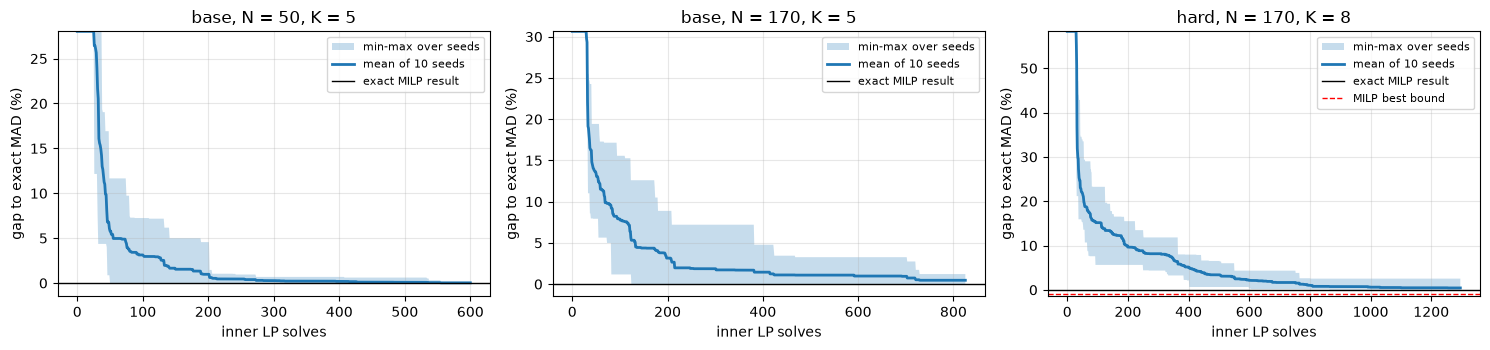

In [22]:
def best_so_far_curve(hist, grid):
    # best feasible MAD after g inner solves, for every g in grid
    idx = np.searchsorted(hist[:, 0], grid, side="right") - 1
    return hist[np.clip(idx, 0, None), 1]


show = [key for key in [("base", 50, 0), ("base", 170, 0), ("hard", 170, 0)] if any(k[:3] == key for k in histories)]
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 3.6), squeeze=False)
for ax, (cfg, n, us) in zip(axes[0], show):
    r = exact[(exact.config == cfg) & (exact.N == n) & (exact.seed == us)].iloc[0]
    grid = np.arange(0, lp_budget(n, int(r.K)) + 1)
    curves = np.array([100 * (best_so_far_curve(histories[(cfg, n, us, s)], grid) - r.objective_mad) / r.objective_mad for s in SA_SEEDS])
    ax.fill_between(grid, curves.min(axis=0), curves.max(axis=0), alpha=0.25, label="min-max over seeds")
    ax.plot(grid, curves.mean(axis=0), lw=2, label=f"mean of {len(SA_SEEDS)} seeds")
    ax.axhline(0, color="k", lw=1, label="exact MILP result")
    if r.status != "Optimal":
        ax.axhline(100 * (r.best_bound - r.objective_mad) / r.objective_mad, color="r", ls="--", lw=1, label="MILP best bound")
    ax.set_ylim(min(-1.5, curves.min() - 0.2), max(5, np.percentile(curves[:, 1:], 99)))
    ax.set_xlabel("inner LP solves"); ax.set_ylabel("gap to exact MAD (%)")
    ax.set_title(f"{cfg}, N = {n}, K = {int(r.K)}"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

*Figure 1. Convergence of SA: best feasible MAD found so far, as a gap to the exact MILP value, against the number of inner LP solves (mean and min-max band over the seeds). The x-axis ends at the budget; runs stopped by temperature end earlier. For hard N = 170 the dashed line is the MILP's best bound: no solution can lie below it.*

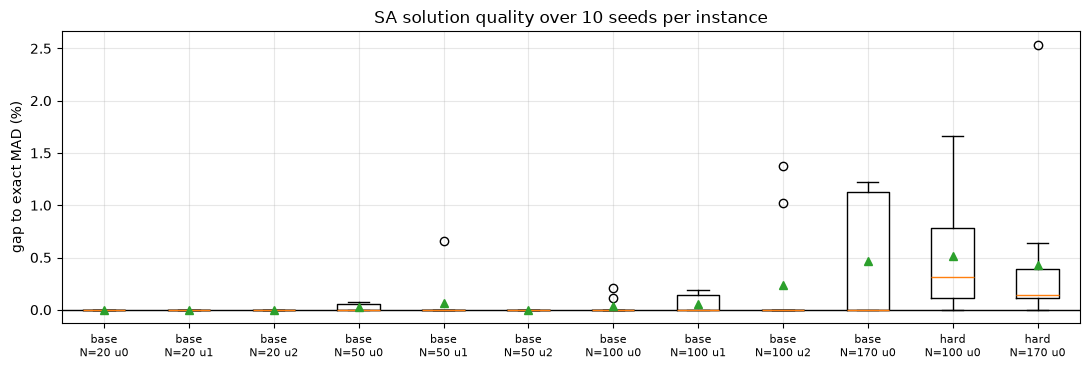

In [23]:
labels, data = [], []
for (cfg, n, us), g in heur.groupby(["config", "N", "universe_seed"], sort=False):
    labels.append(f"{cfg}\nN={n} u{us}"); data.append(g.gap_vs_exact_pct.to_numpy())
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.boxplot(data, showmeans=True)
ax.set_xticks(range(1, len(labels) + 1), labels, fontsize=8)
ax.axhline(0, color="k", lw=1)
ax.set_ylabel("gap to exact MAD (%)"); ax.set_title(f"SA solution quality over {len(SA_SEEDS)} seeds per instance")
plt.tight_layout()
plt.show()

*Figure 2. Gap of each SA run to the exact MILP value, per instance (box = quartiles, triangle = mean). A box collapsed onto 0 means every seed found the exact optimum. A value below 0 is possible only where the MILP stopped at its time limit.*

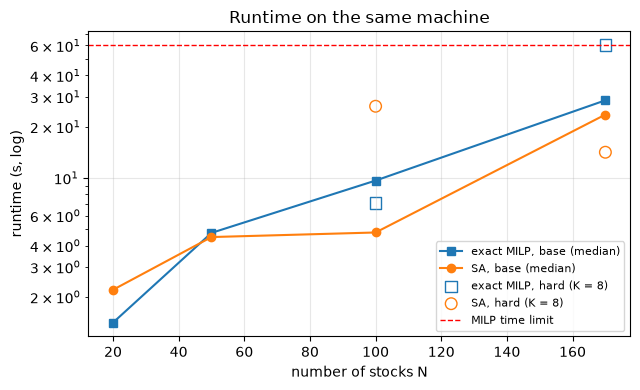

In [24]:
rt = (heur.groupby(["config", "N"]).agg(sa=("runtime_s", "median"), exact_local=("exact_runtime_local_s", "median"))).reset_index()
fig, ax = plt.subplots(figsize=(6.5, 4))
b, h = rt[rt.config == "base"], rt[rt.config == "hard"]
ax.plot(b.N, b.exact_local, "s-", label="exact MILP, base (median)")
ax.plot(b.N, b.sa, "o-", label="SA, base (median)")
if len(h):
    ax.scatter(h.N, h.exact_local, marker="s", s=70, facecolors="none", edgecolors="C0", label="exact MILP, hard (K = 8)")
    ax.scatter(h.N, h.sa, marker="o", s=70, facecolors="none", edgecolors="C1", label="SA, hard (K = 8)")
ax.axhline(TIME_LIMIT, color="r", ls="--", lw=1, label="MILP time limit")
ax.set_yscale("log"); ax.set_xlabel("number of stocks N"); ax.set_ylabel("runtime (s, log)")
ax.set_title("Runtime on the same machine"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

*Figure 3. Wall-clock runtime of the exact MILP (re-run on this machine) and of SA (median over seeds and universes) against problem size. The SA points for base N = 170 and hard N = 100 are inflated by operating-system throttling (section 7.1); with the adjusted runtimes they are 6.4 s and 8.2 s.*

## 10. Findings (heuristic method)

All numbers come from the executed cells above: the same data, universes, constraints and MAD objective as `Exact_Method.ipynb`, 12 reference instances x 10 SA seeds, all on one machine (the environment cell prints it).

1. **Identical inputs.** The rebuilt return targets match the saved ones to about 1e-16, and the inner LP on the MILP's chosen stocks reproduces all 12 exact objectives (largest difference 4.6e-10). The exact MILP re-run on this machine gives the same 12 objectives and the same statuses (hard N = 170 again stops at the 60 s limit).
2. **Inner solver.** The sparse $p - n$ form gives the same optimum as the verbatim LP (difference 1.9e-10) and is about 17 % faster (9.5 against 11.4 ms per solve). The analytic feasibility test agrees with the LP on all 260 test subsets and costs about 6 microseconds. None of 200 random 5-subsets meets the base return target, so screening swaps without an LP matters.
3. **Feasibility.** All 120 SA portfolios pass the independent check and hold exactly K stocks.
4. **Quality.** Every instance's optimum was found by at least one seed (best gap 0 %). The mean gap over seeds is 0 % at N = 20, 0.00 to 0.07 % at N = 50, 0.03 to 0.24 % at N = 100 and 0.47 % at N = 170 (base, K = 5), and 0.51 % (N = 100) and 0.43 % (N = 170) in the hard configuration (K = 8). The worst single run is 2.54 % (hard N = 170). 89 of the 120 runs return exactly the MILP's subset. The gap grows with N and K because the swap neighbourhood $K(N-K)$ grows faster than the LP budget. (The tiny negative gap of -6e-6 % at base N = 20 universe 1 is within the MILP's relative tolerance of 1e-4.)
5. **Hard N = 170, where the MILP did not prove optimality.** The best SA runs (2 of 10) reach exactly the MILP incumbent, MAD 0.0071953, which is 0.95 % above the MILP's best bound. No run found anything better, so this experiment gives no evidence that the incumbent is sub-optimal. SA needs 14.1 s (median) against the MILP's 60 s, about **4.3 times faster**, for a mean gap of 0.43 %.
6. **Speed (same machine, adjusted as in section 7.1).** SA is *slower* than the MILP for small problems: 0.5 to 0.8 times the MILP's speed at N = 20, and about even at N = 50 (0.5 to 1.1). It is faster at N = 100 (1.4 to 2.3 times) and N = 170 (4.5 times: 6.4 s against 28.6 s). In the hard configuration at N = 100 the MILP (7.1 s) is still faster than SA (8.2 s). SA's runtime is set by its LP budget (about 8 ms per LP for K = 5, 11 ms for K = 8), while the MILP's grows faster with N. This matches Lecture 1 slides 55-57: a heuristic pays off only once the exact method becomes expensive.
7. **Ablation: SA adds no quality beyond a local optimum here.** Top-K stocks with equal weights are 14 to 81 % worse than the optimum. LP weights on the same stocks are still 5 to 58 % worse, so *which* stocks are held matters more than the weights. **First-improvement swap local search from the top-K start reaches the exact optimum on all 12 instances**, using 74 to 2,967 LPs (0.6 to 33.6 s). SA (best of 10 seeds) also reaches it, but its average is worse than local search on 8 of the 9 instances from N = 50 up (equal on the ninth). SA is cheaper only where its budget is smaller than the local-search path, as at hard N = 170 (SA 14 s at a 0.43 % mean gap against local search's 33.6 s at 0 %). Interpretation: from the top-K start, the swap landscape of these instances has no poor local optima (Lecture 1 slides 65-66). SA's deliberate worsening moves therefore cost LPs without escaping anything. This is an instance of the no-free-lunch theorem (Lecture 1 slides 70-71): a more elaborate metaheuristic is not automatically better than simple descent.

**Limits and threats to validity.** One machine; 27 runs re-timed from their LP counts (section 7.1). One tuning universe, which shares up to 66 % of its stocks with a reported universe, unavoidable when only 170 stocks exist. Only subsets of exactly K stocks are searched (every exact solution held K, but this is not guaranteed in general). The budget rule $\max(600, K(N-K))$ was set by reasoning, not tuned. The penalty variant was tried with a single $\rho$. The same in-sample window and MAD objective as the exact notebook, so the exact notebook's limits (survivorship bias, no out-of-sample test) apply here too.

**Future work.** Finish SA with a swap descent from its best subset (an SA + local search hybrid). A genetic algorithm once that lecture is delivered. A cooling schedule tied to the budget, so every run ends cold. Swaps biased towards stocks with low correlation to the portfolio. A warm-started LP (for example `highspy`) to cut the cost per solve. Larger, harder instances (more stocks or a longer window) where the MILP times out more often.